In [9]:
from dotenv import load_dotenv
from sqlalchemy import create_engine
import os

load_dotenv()

engine = create_engine(
    f"postgresql+psycopg2://"
    f"{os.getenv('DB_USER')}:{os.getenv('DB_PASSWORD')}"
    f"@{os.getenv('DB_HOST')}:{os.getenv('DB_PORT')}"
    f"/{os.getenv('DB_NAME')}"
)

with engine.connect() as conn:
    from sqlalchemy import text
    result = conn.execute(text("SELECT 1"))
    print("✅ Conexão OK!", result.fetchone())

✅ Conexão OK! (1,)


In [2]:
import pandas as pd

In [3]:
# Carrega as 3 tabelas em DataFrames

exercicios = pd.read_sql("SELECT * FROM exercicios", engine)
treinos = pd.read_sql("SELECT * FROM treinos", engine)
series = pd.read_sql('SELECT * FROM series', engine)

# Confirma o que veio
print("exercicios:", exercicios.shape)
print("treinos:   ", treinos.shape)
print("series:    ", series.shape)

exercicios: (12, 3)
treinos:    (16, 4)
series:     (114, 6)


In [4]:
# Estrutura de cada tabela
print("=== EXERCICIOS ===")
print(exercicios.head())
print("\n=== TREINOS ===")
print(treinos.head())
print("\n=== SERIES ===")
print(series.head())

=== EXERCICIOS ===
   id              nome grupo_muscular
0   2       Supino Reto          Peito
1   3  Supino Inclinado          Peito
2   4         Crucifixo          Peito
3   5       Agachamento         Pernas
4   6         Leg Press         Pernas

=== TREINOS ===
   id        data  duracao_min        observacao
0   2  2026-01-05           45  Aquecimento leve
1   3  2026-01-07           60                  
2   4  2026-01-09           50                  
3   5  2026-01-12           48                  
4   6  2026-01-14           62                  

=== SERIES ===
   id  treino_id  exercicio_id  numero_serie  repeticoes  peso_kg
0   1          2             2             1          10     80.0
1   2          2             2             2           8     90.0
2   3          2             2             3           6     95.0
3   4          2             3             1          10     70.0
4   5          2             3             2           8     75.0


In [5]:
# Juntar as 3 tabelas

df = ( series
.merge(exercicios, left_on='exercicio_id', right_on='id', suffixes=("","_ex"))
.merge(treinos,    left_on="treino_id",    right_on="id", suffixes=("", "_tr"))
)
# Colunas úteis
df = df[["treino_id", "data", "duracao_min", "nome", "grupo_muscular","numero_serie", "repeticoes", "peso_kg"]]

print(df.shape)
print(df.head())

(114, 8)
   treino_id        data  duracao_min              nome grupo_muscular  \
0          2  2026-01-05           45       Supino Reto          Peito   
1          2  2026-01-05           45       Supino Reto          Peito   
2          2  2026-01-05           45       Supino Reto          Peito   
3          2  2026-01-05           45  Supino Inclinado          Peito   
4          2  2026-01-05           45  Supino Inclinado          Peito   

   numero_serie  repeticoes  peso_kg  
0             1          10     80.0  
1             2           8     90.0  
2             3           6     95.0  
3             1          10     70.0  
4             2           8     75.0  


In [6]:
volume = (df.groupby("grupo_muscular")["numero_serie"]
            .count()
            .reset_index()
            .rename(columns={"numero_serie": "total_series"})
            .sort_values("total_series", ascending=False)
)

print(volume)

  grupo_muscular  total_series
3          Peito            36
0         Costas            30
4         Pernas            24
2          Ombro            12
5     Quadriceps             9
1  Isquiotibiais             3


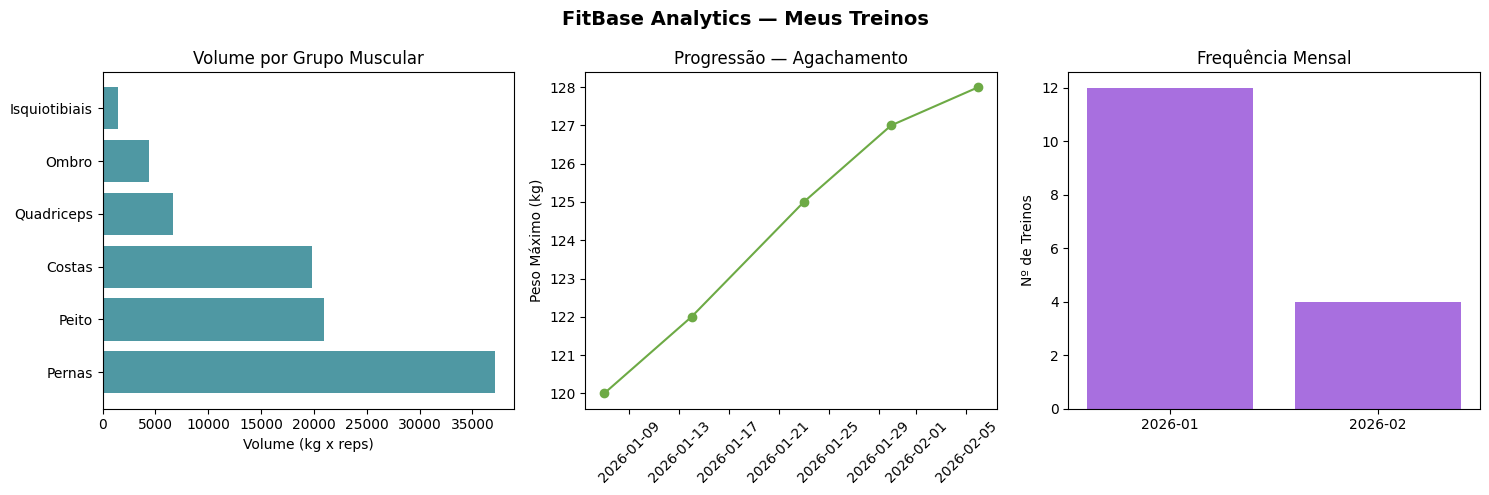

✅ Análise concluída! Gráficos salvos.


In [7]:
df_vol = pd.read_sql("""
    SELECT e.grupo_muscular,
           SUM(s.repeticoes * s.peso_kg) AS volume
    FROM series s
    JOIN exercicios e ON s.exercicio_id = e.id
    GROUP BY e.grupo_muscular
    ORDER BY volume DESC
""", engine)

# ── PERGUNTA 2: Progressão do Agachamento ─────────────
df_squat = pd.read_sql("""
    SELECT t.data, MAX(s.peso_kg) AS peso_max
    FROM series s
    JOIN treinos t    ON s.treino_id = t.id
    JOIN exercicios e ON s.exercicio_id = e.id
    WHERE e.nome = 'Agachamento'
    GROUP BY t.data ORDER BY t.data
""", engine)

# ── PERGUNTA 3: Treinos por mês ───────────────────────
df_mes = pd.read_sql("""
    SELECT TO_CHAR(data, 'YYYY-MM') AS mes,
        COUNT(*) AS num_treinos
    FROM treinos
    GROUP BY mes ORDER BY mes
""", engine)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle('FitBase Analytics — Meus Treinos', fontsize=14, fontweight='bold')

# Gráfico 1: Volume por grupo muscular
axes[0].barh(df_vol['grupo_muscular'], df_vol['volume'], color='#4f98a3')
axes[0].set_title('Volume por Grupo Muscular')
axes[0].set_xlabel('Volume (kg x reps)')

# Gráfico 2: Progressão do Agachamento
axes[1].plot(df_squat['data'], df_squat['peso_max'], 'o-', color='#6daa45')
axes[1].set_title('Progressão — Agachamento')
axes[1].set_ylabel('Peso Máximo (kg)')
axes[1].tick_params(axis='x', rotation=45)

# Gráfico 3: Treinos por mês
axes[2].bar(df_mes['mes'], df_mes['num_treinos'], color='#a86fdf')
axes[2].set_title('Frequência Mensal')
axes[2].set_ylabel('Nº de Treinos')

plt.tight_layout()
plt.savefig('assets/analise_treinos.png', dpi=150)
plt.show()
print("✅ Análise concluída! Gráficos salvos.")

In [8]:
from dotenv import load_dotenv
import os

load_dotenv()

print(os.getenv("DB_NAME"))
print(os.getenv("DB_USER"))    # fituser
print(os.getenv("DB_PASSWORD") is not None)  

fitbase
fituser
True
